# Restaurant Dataset - Geospatial Analysis

Level 1 - Task 3

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

pd.set_option("display.max_columns", None)

In [9]:
df = pd.read_csv("../Cleaned_Dataset.csv")

df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",1500,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",1500,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [10]:
df[["Latitude", "Longitude"]].describe()

,Latitude,Longitude
count,9551.000000,9551.000000
mean,25.854381,64.126574
std,11.007935,41.467058
min,-41.330428,-157.948486
25%,28.478713,77.081343
50%,28.570469,77.191964
75%,28.642758,77.282006
max,55.976980,174.832089


In [11]:
df[["Latitude", "Longitude"]].isnull().sum()

Latitude     0
Longitude    0
dtype: int64

In [12]:
restaurant_map = folium.Map(
    location=[
        df["Latitude"].mean(),
        df["Longitude"].mean()
    ],
    zoom_start=4
)

In [17]:
sample_df = df.sample(
    min(500, len(df)),
    random_state=42
)

for _, row in sample_df.iterrows():
    folium.CircleMarker(
        location=[row["Latitude"], row["Longitude"]],
        radius=3,
        popup=row["Restaurant Name"],
        fill=True
    ).add_to(restaurant_map)
restaurant_map.save("map.html")

In [18]:
country_counts = df["Country Code"].value_counts()

country_counts

Country Code
1      8652
216     434
215      80
30       60
214      60
189      60
148      40
208      34
14       24
162      22
94       21
184      20
166      20
191      20
37        4
Name: count, dtype: int64

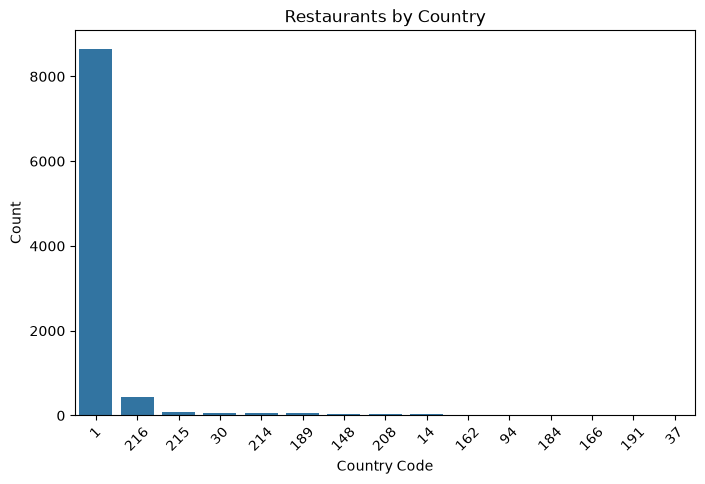

In [19]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=country_counts.index.astype(str),
    y=country_counts.values
)

plt.title("Restaurants by Country")
plt.xlabel("Country Code")
plt.ylabel("Count")

plt.xticks(rotation=45)

plt.show()

In [20]:
city_counts = df["City"].value_counts()

city_counts.head(15)

City
New Delhi         5473
Gurgaon           1118
Noida             1080
Faridabad          251
Ghaziabad           25
Ahmedabad           21
Amritsar            21
Bhubaneshwar        21
Guwahati            21
Lucknow             21
Bras�_lia           20
Rio de Janeiro      20
S��o Paulo          20
Albany              20
Athens              20
Name: count, dtype: int64

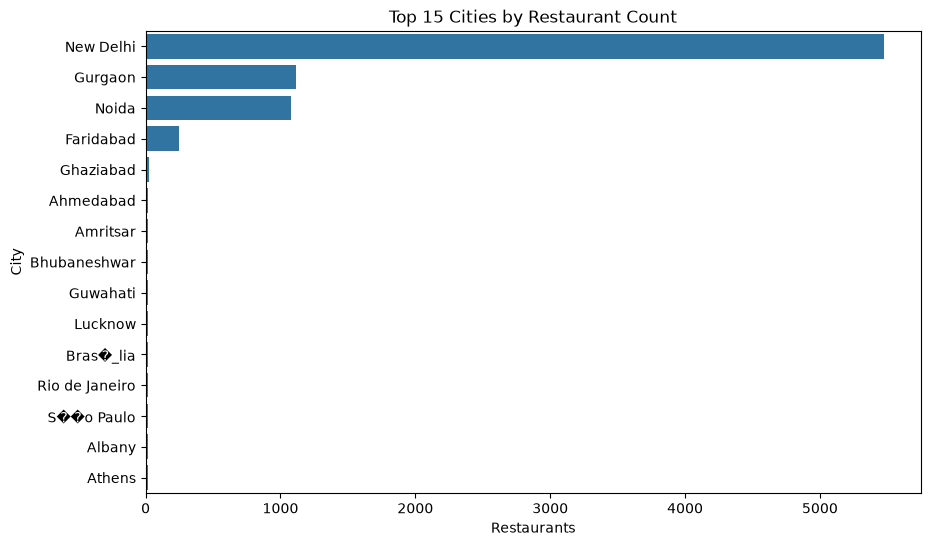

In [21]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=city_counts.head(15).values,
    y=city_counts.head(15).index
)

plt.title("Top 15 Cities by Restaurant Count")
plt.xlabel("Restaurants")

plt.show()

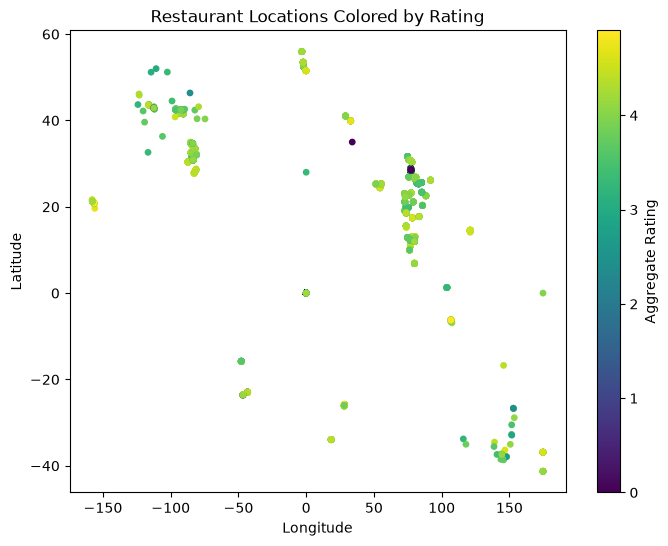

In [22]:
plt.figure(figsize=(8,6))

plt.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df["Aggregate rating"],
    cmap="viridis",
    s=15
)

plt.colorbar(label="Aggregate Rating")

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Restaurant Locations Colored by Rating")

plt.show()

In [23]:
df[
    [
        "Latitude",
        "Longitude",
        "Aggregate rating"
    ]
].corr()

,Latitude,Longitude,Aggregate rating
Latitude,1.000000,0.043207,0.000516
Longitude,0.043207,1.000000,-0.116818
Aggregate rating,0.000516,-0.116818,1.000000


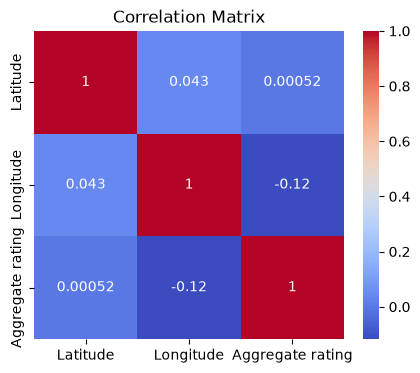

In [24]:
plt.figure(figsize=(5,4))

sns.heatmap(
    df[
        [
            "Latitude",
            "Longitude",
            "Aggregate rating"
        ]
    ].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()

## Geospatial Insights

- Restaurants are concentrated in a limited number of cities.
- Some countries contain significantly more restaurants than others.
- Latitude and longitude alone show little linear correlation with aggregate rating.
- Restaurant quality appears to depend more on business-related factors than geographic coordinates.